In [5]:
!pip install xgboost

In [6]:
from xgboost import XGBRegressor

In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor

import matplotlib.pyplot as plt

In [8]:
data = pd.read_csv(
    r"C:\Users\pilli\Downloads\M5_Thesis_Project\data\processed\feature_engineered_data.csv"
)

print(data.shape)

data.head()

(1610, 30)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,snap_WI,sell_price,week,lag_7,lag_28,rolling_mean_7,rolling_mean_28,is_weekend,month_start,month_end
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1178,0,2014-04-20,11412,...,0,8.26,16,0.0,0.0,0.571429,0.392857,0,0,0
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1234,2,2014-06-15,11420,...,1,8.26,24,0.0,1.0,0.428571,0.428571,0,0,0
2,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_828,1,2013-05-05,11315,...,1,3.97,18,0.0,0.0,0.142857,0.142857,0,0,0
3,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1178,0,2014-04-20,11412,...,0,3.97,16,0.0,0.0,0.142857,0.142857,0,0,0
4,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1234,0,2014-06-15,11420,...,1,3.97,24,2.0,0.0,0.571429,0.500000,0,0,0


In [9]:
features = [
    'sell_price',
    'week',
    'lag_7',
    'lag_28',
    'rolling_mean_7',
    'rolling_mean_28',
    'snap_CA',
    'snap_TX',
    'snap_WI',
    'month',
    'year',
    'wday'
]

X = data[features]

y = data['sales']

print(X.shape)
print(y.shape)

(1610, 12)
(1610,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(1288, 12)
(322, 12)


In [11]:
xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [12]:
predictions = xgb_model.predict(X_test)

print(predictions[:10])

[0.681839   0.6273422  0.23485567 0.35050076 0.7327256  2.963092
 0.14920083 0.34578148 0.57240903 0.27854446]


In [13]:
mae_xgb = mean_absolute_error(
    y_test,
    predictions
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

print("XGBoost MAE:", mae_xgb)
print("XGBoost RMSE:", rmse_xgb)

XGBoost MAE: 1.092314671717804
XGBoost RMSE: 3.5866100084583037


In [21]:
import os

os.makedirs(
    r"C:\Users\pilli\Downloads\M5_Thesis_Project\results\metrics",
    exist_ok=True
)

In [23]:
xgb_metrics = pd.DataFrame({
    'Model': ['XGBoost'],
    'MAE': [mae_xgb],
    'RMSE': [rmse_xgb]
})

xgb_metrics.to_csv(
    r"C:\Users\pilli\Downloads\M5_Thesis_Project\results\metrics\xgboost_metrics.csv",
    index=False
)

xgb_metrics

,Model,MAE,RMSE
0,XGBoost,1.092315,3.58661


In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import os

BASE_PATH = r'C:\Users\pilli\Downloads\M5_Thesis_Project'

xgb_preds = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'xgb_predictions_v4.csv'))

corrected_mae = mean_absolute_error(xgb_preds['sales'], xgb_preds['xgb_pred'])
corrected_rmse = np.sqrt(mean_squared_error(xgb_preds['sales'], xgb_preds['xgb_pred']))

print("="*60)
print("CORRECTED XGBOOST METRICS (SKU-LEVEL)")
print("="*60)
print(f"XGBoost MAE:  {corrected_mae:.4f}")
print(f"XGBoost RMSE: {corrected_rmse:.4f}")

results_df = pd.DataFrame({
    'Model': ['XGBoost'],
    'MAE': [f"{corrected_mae:.4f}"],
    'RMSE': [f"{corrected_rmse:.4f}"]
})

print("\nTABLE FOR THESIS:")
print(results_df.to_string(index=False))

CORRECTED XGBOOST METRICS (SKU-LEVEL)
XGBoost MAE:  0.9814
XGBoost RMSE: 2.2702

TABLE FOR THESIS:
  Model    MAE   RMSE
XGBoost 0.9814 2.2702


✅ Saved: xgb_forecast_vs_actual_CORRECTED.png


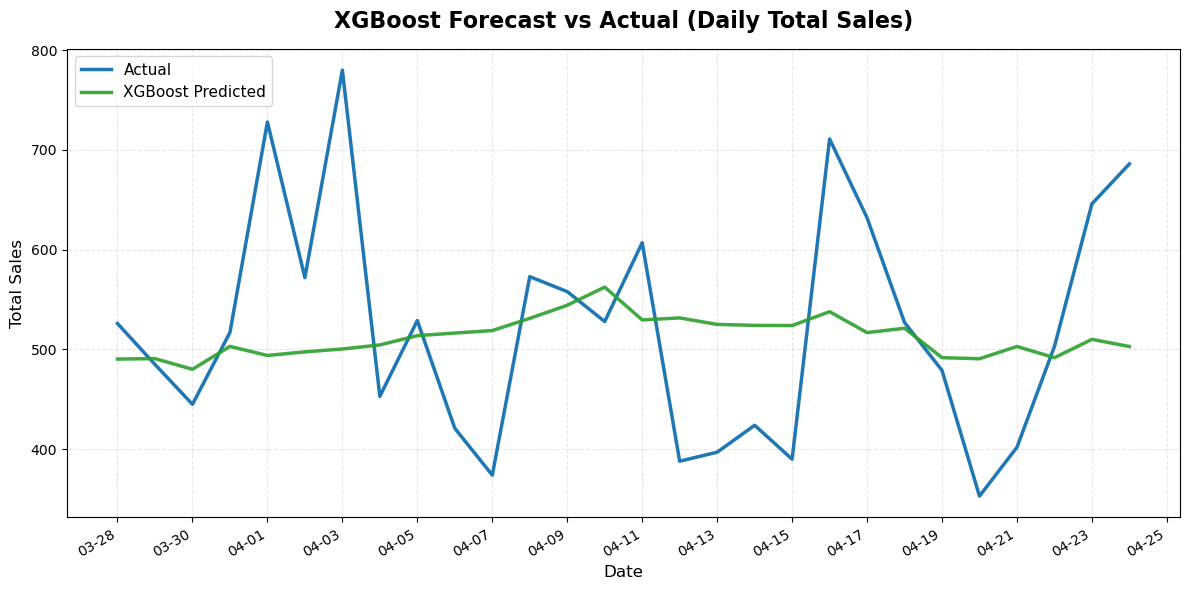

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

xgb_preds = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'xgb_predictions_v4.csv'))
xgb_preds['date'] = pd.to_datetime(xgb_preds['date'])

daily_actual = xgb_preds.groupby('date')['sales'].sum()
daily_pred = xgb_preds.groupby('date')['xgb_pred'].sum()

plt.figure(figsize=(12, 6))
plt.plot(daily_actual.index, daily_actual.values, label='Actual', linewidth=2.5, color='#1f77b4')
plt.plot(daily_pred.index, daily_pred.values, label='XGBoost Predicted', linewidth=2.5, color='#2ca02c', alpha=0.9)

plt.title('XGBoost Forecast vs Actual (Daily Total Sales)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Sales', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))

plt.legend(fontsize=11, loc='upper left')
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()

plt.savefig(os.path.join(BASE_PATH, 'results', 'figures', 'xgb_forecast_vs_actual_CORRECTED.png'), dpi=300, bbox_inches='tight')
print("✅ Saved: xgb_forecast_vs_actual_CORRECTED.png")
plt.show()